# Tugas 3 IF4073 Pemrosesan Citra Digital

1. **Backbone CNN: `DeepLabV3+` + `ResNet-101` Pretrained ImageNet**
2. **Resolusi Input `480 × 640`**

## 1. Cek GPU & Instalasi Dependensi

In [1]:
!nvidia-smi
!pip install -q segmentation-models-pytorch pandas

Wed Nov 25 07:52:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Import Library & Konfigurasi Global (v3)

In [ ]:
import os
import random
import subprocess
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp

# Reproducibility & Konfigurasi
SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True

seed_everything(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device aktif: {DEVICE}")
if DEVICE.type != "cuda":
    print("PERINGATAN: GPU tidak terdeteksi! Aktifkan GPU di Runtime -> Change runtime type -> T4 GPU.")

# Konfigurasi Model & Resolusi
ENCODER_NAME = "resnet101"
IMG_HEIGHT = 480          # Kelipatan 32, rasio 3:4 presisi seperti CamVid asli (720x960)
IMG_WIDTH = 640
NUM_CLASSES = 11          # 11 kelas CamVid sesuai spesifikasi tugas
IGNORE_INDEX = 255        # Label piksel Void diabaikan saat hitung loss

# Hyperparameters Training
BATCH_SIZE = 6
EPOCHS = 55
LEARNING_RATE = 3e-4
ENCODER_LR_MULT = 0.25
WEIGHT_DECAY = 1e-4
GRAD_CLIP_NORM = 1.0

OUTPUT_DIR = Path("/content/camvid_outputs_v3")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = OUTPUT_DIR / "best_deeplabv3plus_resnet101_camvid_v3.pth"

Device aktif: cuda


## 3. Unduh Dataset CamVid dari GitHub (`PengKiKi/camvid`)

In [3]:
DATA_ROOT = Path("/content/camvid")

if not DATA_ROOT.exists():
    print("Mengunduh dataset dari https://github.com/PengKiKi/camvid ...")
    subprocess.run(
        ["git", "clone", "--depth", "1", "https://github.com/PengKiKi/camvid.git", str(DATA_ROOT)],
        check=True,
    )
else:
    print("Folder dataset /content/camvid sudah ada.")

IMG_DIR = DATA_ROOT / "701_StillsRaw_full"
MASK_DIR = DATA_ROOT / "LabeledApproved_full"

assert IMG_DIR.exists(), f"Folder citra tidak ditemukan di {IMG_DIR}"
assert MASK_DIR.exists(), f"Folder label tidak ditemukan di {MASK_DIR}"

img_files = sorted(IMG_DIR.glob("*.png"))
mask_files = sorted(MASK_DIR.glob("*.png"))
print(f"Total citra mentah ditemukan : {len(img_files)}")
print(f"Total citra label ditemukan  : {len(mask_files)}")

Mengunduh dataset dari https://github.com/PengKiKi/camvid ...
Total citra mentah ditemukan : 701
Total citra label ditemukan  : 701


## 4. Pemetaan 32 Kelas CamVid ke 11 Kelas Standar

Mengikuti pengelompokan resmi SegNet / MathWorks:
- **Sky (0):** Sky
- **Building (1):** Bridge, Building, Wall, Tunnel, Archway
- **Pole (2):** Column_Pole, TrafficCone
- **Road (3):** Road, LaneMkgsDriv, LaneMkgsNonDriv
- **Pavement (4):** Sidewalk, ParkingBlock, RoadShoulder
- **Tree (5):** Tree, VegetationMisc *(mencakup semak & grass patch / rumput)*
- **SignSymbol (6):** SignSymbol, Misc_Text, TrafficLight
- **Fence (7):** Fence
- **Car (8):** Car, SUVPickupTruck, Truck_Bus, Train, OtherMoving *(mencakup mobil, SUV, truk, bus)*
- **Pedestrian (9):** Pedestrian, Child, CartLuggagePram, Animal
- **Bicyclist (10):** Bicyclist, MotorcycleScooter
- **Void (255 / ignore):** Void `(0, 0, 0)`

In [4]:
CLASS_NAMES = [
    "Sky",         # 0
    "Building",    # 1
    "Pole",        # 2
    "Road",        # 3
    "Pavement",    # 4
    "Tree",        # 5 (termasuk VegetationMisc / grass patch)
    "SignSymbol",  # 6
    "Fence",       # 7
    "Car",         # 8 (termasuk Truck_Bus, SUVPickupTruck, dll.)
    "Pedestrian",  # 9
    "Bicyclist",   # 10 (termasuk MotorcycleScooter)
]

CLASS_COLORS = np.array([
    [128, 128, 128],  # 0: Sky
    [128,   0,   0],  # 1: Building
    [192, 192, 128],  # 2: Pole
    [128,  64, 128],  # 3: Road
    [  0,   0, 192],  # 4: Pavement
    [128, 128,   0],  # 5: Tree / Vegetation
    [192, 128, 128],  # 6: SignSymbol
    [ 64,  64, 128],  # 7: Fence
    [ 64,   0, 128],  # 8: Car / Bus / Truck
    [ 64,  64,   0],  # 9: Pedestrian
    [  0, 128, 192],  # 10: Bicyclist
], dtype=np.uint8)

RGB_TO_CLASS11 = {
    # 0: Sky
    (128, 128, 128): 0,
    # 1: Building
    (  0, 128,  64): 1,
    (128,   0,   0): 1,
    ( 64, 192,   0): 1,
    ( 64,   0,  64): 1,
    (192,   0, 128): 1,
    # 2: Pole
    (192, 192, 128): 2,
    (  0,   0,  64): 2,
    # 3: Road
    (128,  64, 128): 3,
    (128,   0, 192): 3,
    (192,   0,  64): 3,
    # 4: Pavement
    (  0,   0, 192): 4,
    ( 64, 192, 128): 4,
    (128, 128, 192): 4,
    # 5: Tree / VegetationMisc (rumput)
    (128, 128,   0): 5,
    (192, 192,   0): 5,
    # 6: SignSymbol
    (192, 128, 128): 6,
    (128, 128,  64): 6,
    (  0,  64,  64): 6,
    # 7: Fence
    ( 64,  64, 128): 7,
    # 8: Car / Truck_Bus / SUV
    ( 64,   0, 128): 8,
    ( 64, 128, 192): 8,
    (192, 128, 192): 8,
    (192,  64, 128): 8,
    (128,  64,  64): 8,
    # 9: Pedestrian
    ( 64,  64,   0): 9,
    (192, 128,  64): 9,
    ( 64,   0, 192): 9,
    ( 64, 128,  64): 9,
    # 10: Bicyclist / MotorcycleScooter
    (  0, 128, 192): 10,
    (192,   0, 192): 10,
    # Void
    (  0,   0,   0): IGNORE_INDEX,
}

RGB_LUT = np.full(256 * 256 * 256, IGNORE_INDEX, dtype=np.uint8)
for (r, g, b), cls_id in RGB_TO_CLASS11.items():
    RGB_LUT[(r << 16) | (g << 8) | b] = cls_id


def rgb_mask_to_class_ids(mask_rgb: np.ndarray) -> np.ndarray:
    """Konversi mask RGB CamVid (H, W, 3) menjadi mask indeks kelas (H, W) bernilai 0..10 atau 255."""
    encoded = (
        (mask_rgb[:, :, 0].astype(np.int32) << 16)
        | (mask_rgb[:, :, 1].astype(np.int32) << 8)
        | mask_rgb[:, :, 2].astype(np.int32)
    )
    return RGB_LUT[encoded]


def class_ids_to_rgb(mask_ids: np.ndarray) -> np.ndarray:
    """Konversi mask indeks kelas (H, W) menjadi citra RGB berwarna untuk visualisasi."""
    h, w = mask_ids.shape
    out = np.zeros((h, w, 3), dtype=np.uint8)
    valid = (mask_ids >= 0) & (mask_ids < NUM_CLASSES)
    out[valid] = CLASS_COLORS[mask_ids[valid]]
    return out


PROCESSED_MASK_DIR = Path("/content/camvid_masks_11class")
PROCESSED_MASK_DIR.mkdir(parents=True, exist_ok=True)

pairs = []
missing_masks = 0
for img_path in img_files:
    cand1 = MASK_DIR / f"{img_path.stem}_L.png"
    cand2 = MASK_DIR / img_path.name
    mask_path = cand1 if cand1.exists() else (cand2 if cand2.exists() else None)
    if mask_path is None:
        missing_masks += 1
        continue

    cached_mask_path = PROCESSED_MASK_DIR / f"{img_path.stem}.png"
    if not cached_mask_path.exists():
        mask_bgr = cv2.imread(str(mask_path), cv2.IMREAD_COLOR)
        mask_rgb = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)
        mask_ids = rgb_mask_to_class_ids(mask_rgb)
        cv2.imwrite(str(cached_mask_path), mask_ids)

    pairs.append((str(img_path), str(cached_mask_path)))

print(f"Total pasangan citra-label valid : {len(pairs)} (tanpa label: {missing_masks})")
assert len(pairs) > 0, "Tidak ada pasangan citra dan label yang cocok!"

# Split 60% Train / 20% Validation / 20% Test sesuai referensi MathWorks
train_pairs, temp_pairs = train_test_split(pairs, test_size=0.40, random_state=SEED, shuffle=True)
val_pairs, test_pairs = train_test_split(temp_pairs, test_size=0.50, random_state=SEED, shuffle=True)

print(f"Split Dataset -> Train: {len(train_pairs)} (60%) | Val: {len(val_pairs)} (20%) | Test: {len(test_pairs)} (20%)")

Total pasangan citra-label valid : 701 (tanpa label: 0)
Split Dataset -> Train: 420 (60%) | Val: 140 (20%) | Test: 141 (20%)


## 5. Analisis Distribusi Kelas & Smoothed Median Frequency Balancing

In [5]:
pixel_counts = np.zeros(NUM_CLASSES, dtype=np.int64)
for _, mask_path in train_pairs:
    m = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    for c in range(NUM_CLASSES):
        pixel_counts[c] += np.sum(m == c)

total_valid_pixels = pixel_counts.sum()
freqs = pixel_counts / max(total_valid_pixels, 1)

median_freq = np.median(freqs)
raw_weights = median_freq / np.maximum(freqs, 1e-6)
class_weights = np.clip(np.sqrt(raw_weights), 0.5, 4.0)

df_dist = pd.DataFrame({
    "Kelas": CLASS_NAMES,
    "Jumlah Piksel (Train)": pixel_counts,
    "Proporsi (%)": np.round(freqs * 100, 2),
    "Bobot Loss": np.round(class_weights, 3),
})
display(df_dist)

CLASS_WEIGHTS_TENSOR = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)

,Kelas,Jumlah Piksel (Train),Proporsi (%),Bobot Loss
0,Sky,44760743,15.88,0.542
1,Building,72123221,25.58,0.500
2,Pole,2947028,1.05,2.113
3,Road,84911142,30.12,0.500
4,Pavement,21260876,7.54,0.787
5,Tree,31600950,11.21,0.645
6,SignSymbol,3186347,1.13,2.032
7,Fence,4274279,1.52,1.754
8,Car,13156163,4.67,1.000
9,Pedestrian,2058254,0.73,2.528


## 6. Dataset PyTorch & Augmentasi Tersinkronisasi (Bersih & Tajam)

Menggunakan augmentasi bersih yang terbukti efektif di v1 (Random Horizontal Flip, Random Scale 0.8x–1.4x + Random Crop `480 × 640`, serta Brightness/Contrast/Saturation jitter ringan tanpa mengubah Hue dan tanpa blur) agar tepi objek tipis & celah antar kendaraan tetap tajam.

In [6]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


class CamVidDataset(Dataset):
    def __init__(self, pairs, height=IMG_HEIGHT, width=IMG_WIDTH, is_train=True):
        self.pairs = pairs
        self.height = height
        self.width = width
        self.is_train = is_train

    def __len__(self):
        return len(self.pairs)

    def _augment(self, image: np.ndarray, mask: np.ndarray):
        # 1. Random Horizontal Flip (p = 0.5)
        if random.random() < 0.5:
            image = np.ascontiguousarray(image[:, ::-1, :])
            mask = np.ascontiguousarray(mask[:, ::-1])

        # 2. Random Scale (0.80x - 1.40x) + Pad + Random Crop ke (self.height, self.width)
        scale = random.uniform(0.80, 1.40)
        new_h = max(int(round(self.height * scale)), 1)
        new_w = max(int(round(self.width * scale)), 1)
        image = cv2.resize(image, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (new_w, new_h), interpolation=cv2.INTER_NEAREST)

        pad_h = max(self.height - new_h, 0)
        pad_w = max(self.width - new_w, 0)
        if pad_h > 0 or pad_w > 0:
            image = cv2.copyMakeBorder(
                image, 0, pad_h, 0, pad_w, cv2.BORDER_CONSTANT, value=(0, 0, 0)
            )
            mask = cv2.copyMakeBorder(
                mask, 0, pad_h, 0, pad_w, cv2.BORDER_CONSTANT, value=IGNORE_INDEX
            )

        h_cur, w_cur = mask.shape
        top = random.randint(0, h_cur - self.height)
        left = random.randint(0, w_cur - self.width)
        image = image[top : top + self.height, left : left + self.width]
        mask = mask[top : top + self.height, left : left + self.width]

        # 3. Brightness & Contrast Jitter ringan
        if random.random() < 0.7:
            alpha = random.uniform(0.85, 1.15)
            beta = random.uniform(-16, 16)
            image = np.clip(image.astype(np.float32) * alpha + beta, 0, 255).astype(np.uint8)

        # 4. Saturation Jitter ringan (Hue tetap utuh agar grass patch tetap terpisah dari jalan)
        if random.random() < 0.5:
            hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV).astype(np.float32)
            hsv[:, :, 1] = np.clip(hsv[:, :, 1] * random.uniform(0.85, 1.15), 0, 255)
            image = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)

        return image, mask

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]
        image = cv2.cvtColor(cv2.imread(img_path, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        if self.is_train:
            image, mask = self._augment(image, mask)
        else:
            image = cv2.resize(image, (self.width, self.height), interpolation=cv2.INTER_LINEAR)
            mask = cv2.resize(mask, (self.width, self.height), interpolation=cv2.INTER_NEAREST)

        image = (image.astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
        image_tensor = torch.from_numpy(image.transpose(2, 0, 1)).float()
        mask_tensor = torch.from_numpy(mask.astype(np.int64))
        return image_tensor, mask_tensor, img_path


train_dataset = CamVidDataset(train_pairs, is_train=True)
val_dataset = CamVidDataset(val_pairs, is_train=False)
test_dataset = CamVidDataset(test_pairs, is_train=False)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=True, drop_last=True, persistent_workers=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True, persistent_workers=True
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True, persistent_workers=True
)

sample_x, sample_y, _ = next(iter(train_loader))
print(f"Batch X shape: {tuple(sample_x.shape)} | Batch Y shape: {tuple(sample_y.shape)}")
print(f"Nilai unik label di batch pertama: {torch.unique(sample_y).tolist()}")

Batch X shape: (6, 3, 480, 640) | Batch Y shape: (6, 480, 640)
Nilai unik label di batch pertama: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 255]


## 7. Arsitektur Model (`DeepLabV3+` + `ResNet-101`), Combined Loss & Metrik Evaluasi

- **Model:** `smp.DeepLabV3Plus(encoder_name="resnet101", encoder_weights="imagenet")`: arsitektur *pretrained CNN*
- **Loss:** `0.60 * Weighted Cross-Entropy + 0.40 * Multiclass Dice Loss` (tanpa label smoothing agar tepi tajam)

In [ ]:
def build_model():
    return smp.DeepLabV3Plus(
        encoder_name=ENCODER_NAME,
        encoder_weights="imagenet",
        in_channels=3,
        classes=NUM_CLASSES,
    )


class CombinedSegLoss(nn.Module):
    def __init__(self, class_weights, ignore_index=IGNORE_INDEX, ce_weight=0.6, dice_weight=0.4):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=class_weights, ignore_index=ignore_index)
        self.dice = smp.losses.DiceLoss(mode="multiclass", from_logits=True, ignore_index=ignore_index)
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        return self.ce_weight * self.ce(logits, targets) + self.dice_weight * self.dice(logits, targets)


def compute_confusion_matrix(preds: np.ndarray, targets: np.ndarray, num_classes=NUM_CLASSES):
    valid = (targets >= 0) & (targets < num_classes)
    hist = np.bincount(
        num_classes * targets[valid].astype(np.int64) + preds[valid].astype(np.int64),
        minlength=num_classes ** 2,
    ).reshape(num_classes, num_classes)
    return hist


def metrics_from_confusion_matrix(cm: np.ndarray):
    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp

    denom_iou = tp + fp + fn
    per_class_iou = np.where(denom_iou > 0, tp / np.maximum(denom_iou, 1), np.nan)
    miou = np.nanmean(per_class_iou)

    pixel_acc = tp.sum() / max(cm.sum(), 1)
    per_class_acc = np.where((tp + fn) > 0, tp / np.maximum(tp + fn, 1), np.nan)
    mean_acc = np.nanmean(per_class_acc)

    return {
        "pixel_acc": float(pixel_acc),
        "mean_acc": float(mean_acc),
        "miou": float(miou),
        "per_class_iou": per_class_iou,
        "per_class_acc": per_class_acc,
    }


model = build_model().to(DEVICE)
criterion = CombinedSegLoss(CLASS_WEIGHTS_TENSOR, ignore_index=IGNORE_INDEX)

optimizer = torch.optim.AdamW([
    {"params": model.encoder.parameters(), "lr": LEARNING_RATE * ENCODER_LR_MULT},
    {"params": model.decoder.parameters(), "lr": LEARNING_RATE},
    {"params": model.segmentation_head.parameters(), "lr": LEARNING_RATE},
], weight_decay=WEIGHT_DECAY)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

# Verifikasi forward pass
with torch.no_grad():
    dummy_out = model(sample_x[:2].to(DEVICE))
    assert dummy_out.shape == (2, NUM_CLASSES, IMG_HEIGHT, IMG_WIDTH), f"Unexpected shape: {dummy_out.shape}"

total_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Model DeepLabV3+ ({ENCODER_NAME}) siap! Total parameter: {total_params:.2f} juta")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  179MB            

model.safetensors: downloading bytes:           |  0.00B            

Model DeepLabV3+ (resnet101) siap! Total parameter: 45.67 juta


## 8. Proses Training & Fine-Tuning (AMP GPU, < 1 Menit/Epoch)

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, scaler):
    model.train()
    running_loss = 0.0
    for images, masks, _ in loader:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
            logits = model(images)
            loss = criterion(logits, masks)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
    return running_loss / max(len(loader), 1)


@torch.no_grad()
def forward_multiscale_tta(model, images, scales=(0.75, 1.0, 1.25)):
    _, _, orig_h, orig_w = images.shape
    logits_sum = None
    count = 0

    for sc in scales:
        sh = max(32, int(round(orig_h * sc / 32.0)) * 32)
        sw = max(32, int(round(orig_w * sc / 32.0)) * 32)
        inp = images if (sh == orig_h and sw == orig_w) else F.interpolate(
            images, size=(sh, sw), mode="bilinear", align_corners=False
        )

        out = model(inp)
        if out.shape[-2:] != (orig_h, orig_w):
            out = F.interpolate(out, size=(orig_h, orig_w), mode="bilinear", align_corners=False)

        out_flip = torch.flip(model(torch.flip(inp, dims=[3])), dims=[3])
        if out_flip.shape[-2:] != (orig_h, orig_w):
            out_flip = F.interpolate(out_flip, size=(orig_h, orig_w), mode="bilinear", align_corners=False)

        combined = out + out_flip
        logits_sum = combined if logits_sum is None else (logits_sum + combined)
        count += 2

    return logits_sum / float(count)


@torch.no_grad()
def evaluate(model, loader, criterion, tta_mode="none"):
    model.eval()
    running_loss = 0.0
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)

    for images, masks, _ in loader:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
            if tta_mode == "multiscale":
                logits = forward_multiscale_tta(model, images, scales=(0.75, 1.0, 1.25))
            elif tta_mode == "flip":
                logits = 0.5 * (model(images) + torch.flip(model(torch.flip(images, dims=[3])), dims=[3]))
            else:
                logits = model(images)
            loss = criterion(logits, masks)

        running_loss += loss.item()
        preds = torch.argmax(logits, dim=1).cpu().numpy()
        targets = masks.cpu().numpy()
        cm += compute_confusion_matrix(preds, targets)

    metrics = metrics_from_confusion_matrix(cm)
    metrics["loss"] = running_loss / max(len(loader), 1)
    return metrics


history = {"train_loss": [], "val_loss": [], "val_miou": [], "val_acc": []}
best_miou = 0.0
start_time = time.time()

print(f"Memulai fine-tuning v3 selama {EPOCHS} epoch ({ENCODER_NAME} @ {IMG_HEIGHT}x{IMG_WIDTH})...")
for epoch in range(1, EPOCHS + 1):
    ep_start = time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, scaler)
    val_metrics = evaluate(model, val_loader, criterion, tta_mode="none")
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_metrics["loss"])
    history["val_miou"].append(val_metrics["miou"])
    history["val_acc"].append(val_metrics["pixel_acc"])

    saved_flag = ""
    if val_metrics["miou"] > best_miou:
        best_miou = val_metrics["miou"]
        torch.save({
            "epoch": epoch,
            "arch": "DeepLabV3Plus",
            "encoder_name": ENCODER_NAME,
            "model_state_dict": model.state_dict(),
            "best_miou": best_miou,
            "class_names": CLASS_NAMES,
            "img_height": IMG_HEIGHT,
            "img_width": IMG_WIDTH,
        }, BEST_MODEL_PATH)
        saved_flag = "  <-- [SAVED BEST]"

    ep_time = time.time() - ep_start
    print(
        f"Epoch {epoch:02d}/{EPOCHS:02d} ({ep_time:.1f}s) | "
        f"Train Loss: {train_loss:.4f} | Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Acc: {val_metrics['pixel_acc']*100:.2f}% | Val mIoU: {val_metrics['miou']*100:.2f}%{saved_flag}"
    )

total_min = (time.time() - start_time) / 60.0
print(f"\nTraining v3 selesai dalam {total_min:.2f} menit. Best Val mIoU: {best_miou*100:.2f}%")

Memulai fine-tuning v3 selama 55 epoch (resnet101 @ 480x640)...
Epoch 01/55 (37.9s) | Train Loss: 0.7119 | Val Loss: 0.4250 | Val Acc: 89.75% | Val mIoU: 60.73%  <-- [SAVED BEST]
Epoch 02/55 (29.1s) | Train Loss: 0.3896 | Val Loss: 0.3300 | Val Acc: 91.97% | Val mIoU: 68.17%  <-- [SAVED BEST]
Epoch 03/55 (29.2s) | Train Loss: 0.3080 | Val Loss: 0.2839 | Val Acc: 92.25% | Val mIoU: 69.95%  <-- [SAVED BEST]
Epoch 04/55 (29.0s) | Train Loss: 0.2681 | Val Loss: 0.2605 | Val Acc: 92.84% | Val mIoU: 72.06%  <-- [SAVED BEST]
Epoch 05/55 (29.7s) | Train Loss: 0.2464 | Val Loss: 0.2517 | Val Acc: 93.11% | Val mIoU: 72.69%  <-- [SAVED BEST]
Epoch 06/55 (29.5s) | Train Loss: 0.2312 | Val Loss: 0.2289 | Val Acc: 93.86% | Val mIoU: 74.71%  <-- [SAVED BEST]
Epoch 07/55 (29.3s) | Train Loss: 0.2170 | Val Loss: 0.2352 | Val Acc: 93.71% | Val mIoU: 74.88%  <-- [SAVED BEST]
Epoch 08/55 (29.5s) | Train Loss: 0.2028 | Val Loss: 0.2234 | Val Acc: 93.75% | Val mIoU: 75.69%  <-- [SAVED BEST]
Epoch 09/55 (29.

## 9. Kurva Training & Validasi (Untuk Laporan)

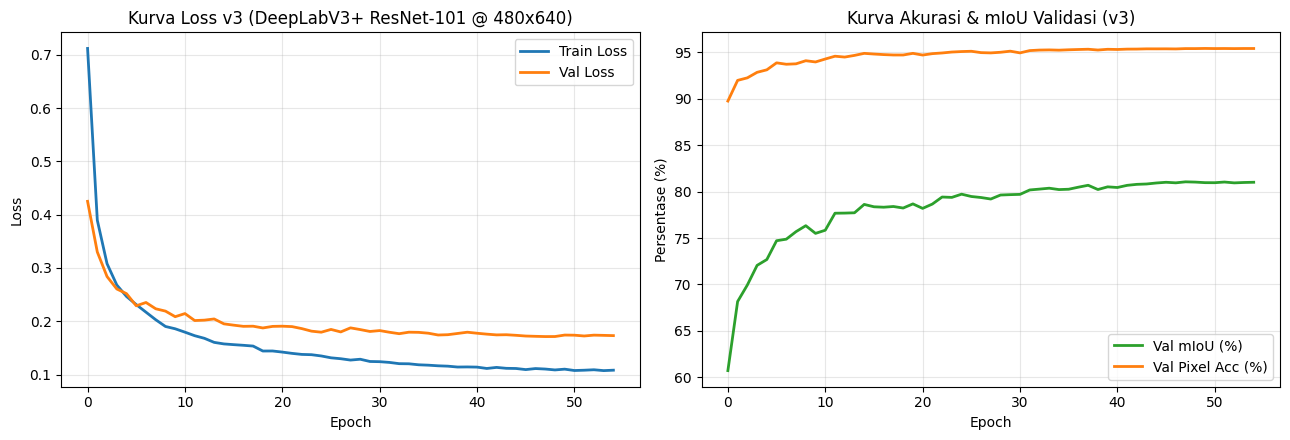

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(history["train_loss"], label="Train Loss", linewidth=2)
axes[0].plot(history["val_loss"], label="Val Loss", linewidth=2)
axes[0].set_title("Kurva Loss v3 (DeepLabV3+ ResNet-101 @ 480x640)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot([v * 100 for v in history["val_miou"]], label="Val mIoU (%)", linewidth=2, color="tab:green")
axes[1].plot([v * 100 for v in history["val_acc"]], label="Val Pixel Acc (%)", linewidth=2, color="tab:orange")
axes[1].set_title("Kurva Akurasi & mIoU Validasi (v3)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Persentase (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves_v3.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Evaluasi Kuantitatif pada Data Uji CamVid (Single-Scale vs Multi-Scale TTA)

In [10]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_metrics_single = evaluate(model, test_loader, criterion, tta_mode="none")
test_metrics_ms = evaluate(model, test_loader, criterion, tta_mode="multiscale")

print("=== PERBANDINGAN HASIL TEST SET (v3) ===")
print(
    f"[Single-Scale]    Pixel Acc: {test_metrics_single['pixel_acc']*100:.2f}% | "
    f"Mean Acc: {test_metrics_single['mean_acc']*100:.2f}% | mIoU: {test_metrics_single['miou']*100:.2f}%"
)
print(
    f"[Multi-Scale TTA] Pixel Acc: {test_metrics_ms['pixel_acc']*100:.2f}% | "
    f"Mean Acc: {test_metrics_ms['mean_acc']*100:.2f}% | mIoU: {test_metrics_ms['miou']*100:.2f}%"
)

df_test = pd.DataFrame({
    "Kelas": CLASS_NAMES,
    "IoU Single (%)": np.round(test_metrics_single["per_class_iou"] * 100, 2),
    "IoU MS-TTA (%)": np.round(test_metrics_ms["per_class_iou"] * 100, 2),
    "Accuracy MS-TTA (%)": np.round(test_metrics_ms["per_class_acc"] * 100, 2),
})
df_test.to_csv(OUTPUT_DIR / "test_metrics_per_class_v3.csv", index=False)
display(df_test)

=== PERBANDINGAN HASIL TEST SET (v3) ===
[Single-Scale]    Pixel Acc: 95.30% | Mean Acc: 90.75% | mIoU: 81.16%
[Multi-Scale TTA] Pixel Acc: 95.53% | Mean Acc: 90.95% | mIoU: 81.92%


,Kelas,IoU Single (%),IoU MS-TTA (%),Accuracy MS-TTA (%)
0,Sky,93.05,93.19,96.17
1,Building,91.68,92.17,95.43
2,Pole,45.55,48.44,75.66
3,Road,97.55,97.68,98.39
4,Pavement,88.27,88.74,95.02
5,Tree,84.62,85.03,91.84
6,SignSymbol,70.13,72.12,84.98
7,Fence,77.43,77.48,85.96
8,Car,91.69,92.09,96.67
9,Pedestrian,70.37,71.86,86.92


## 11. Inferensi & Visualisasi Hasil pada Citra Uji CamVid (Multi-Scale TTA)

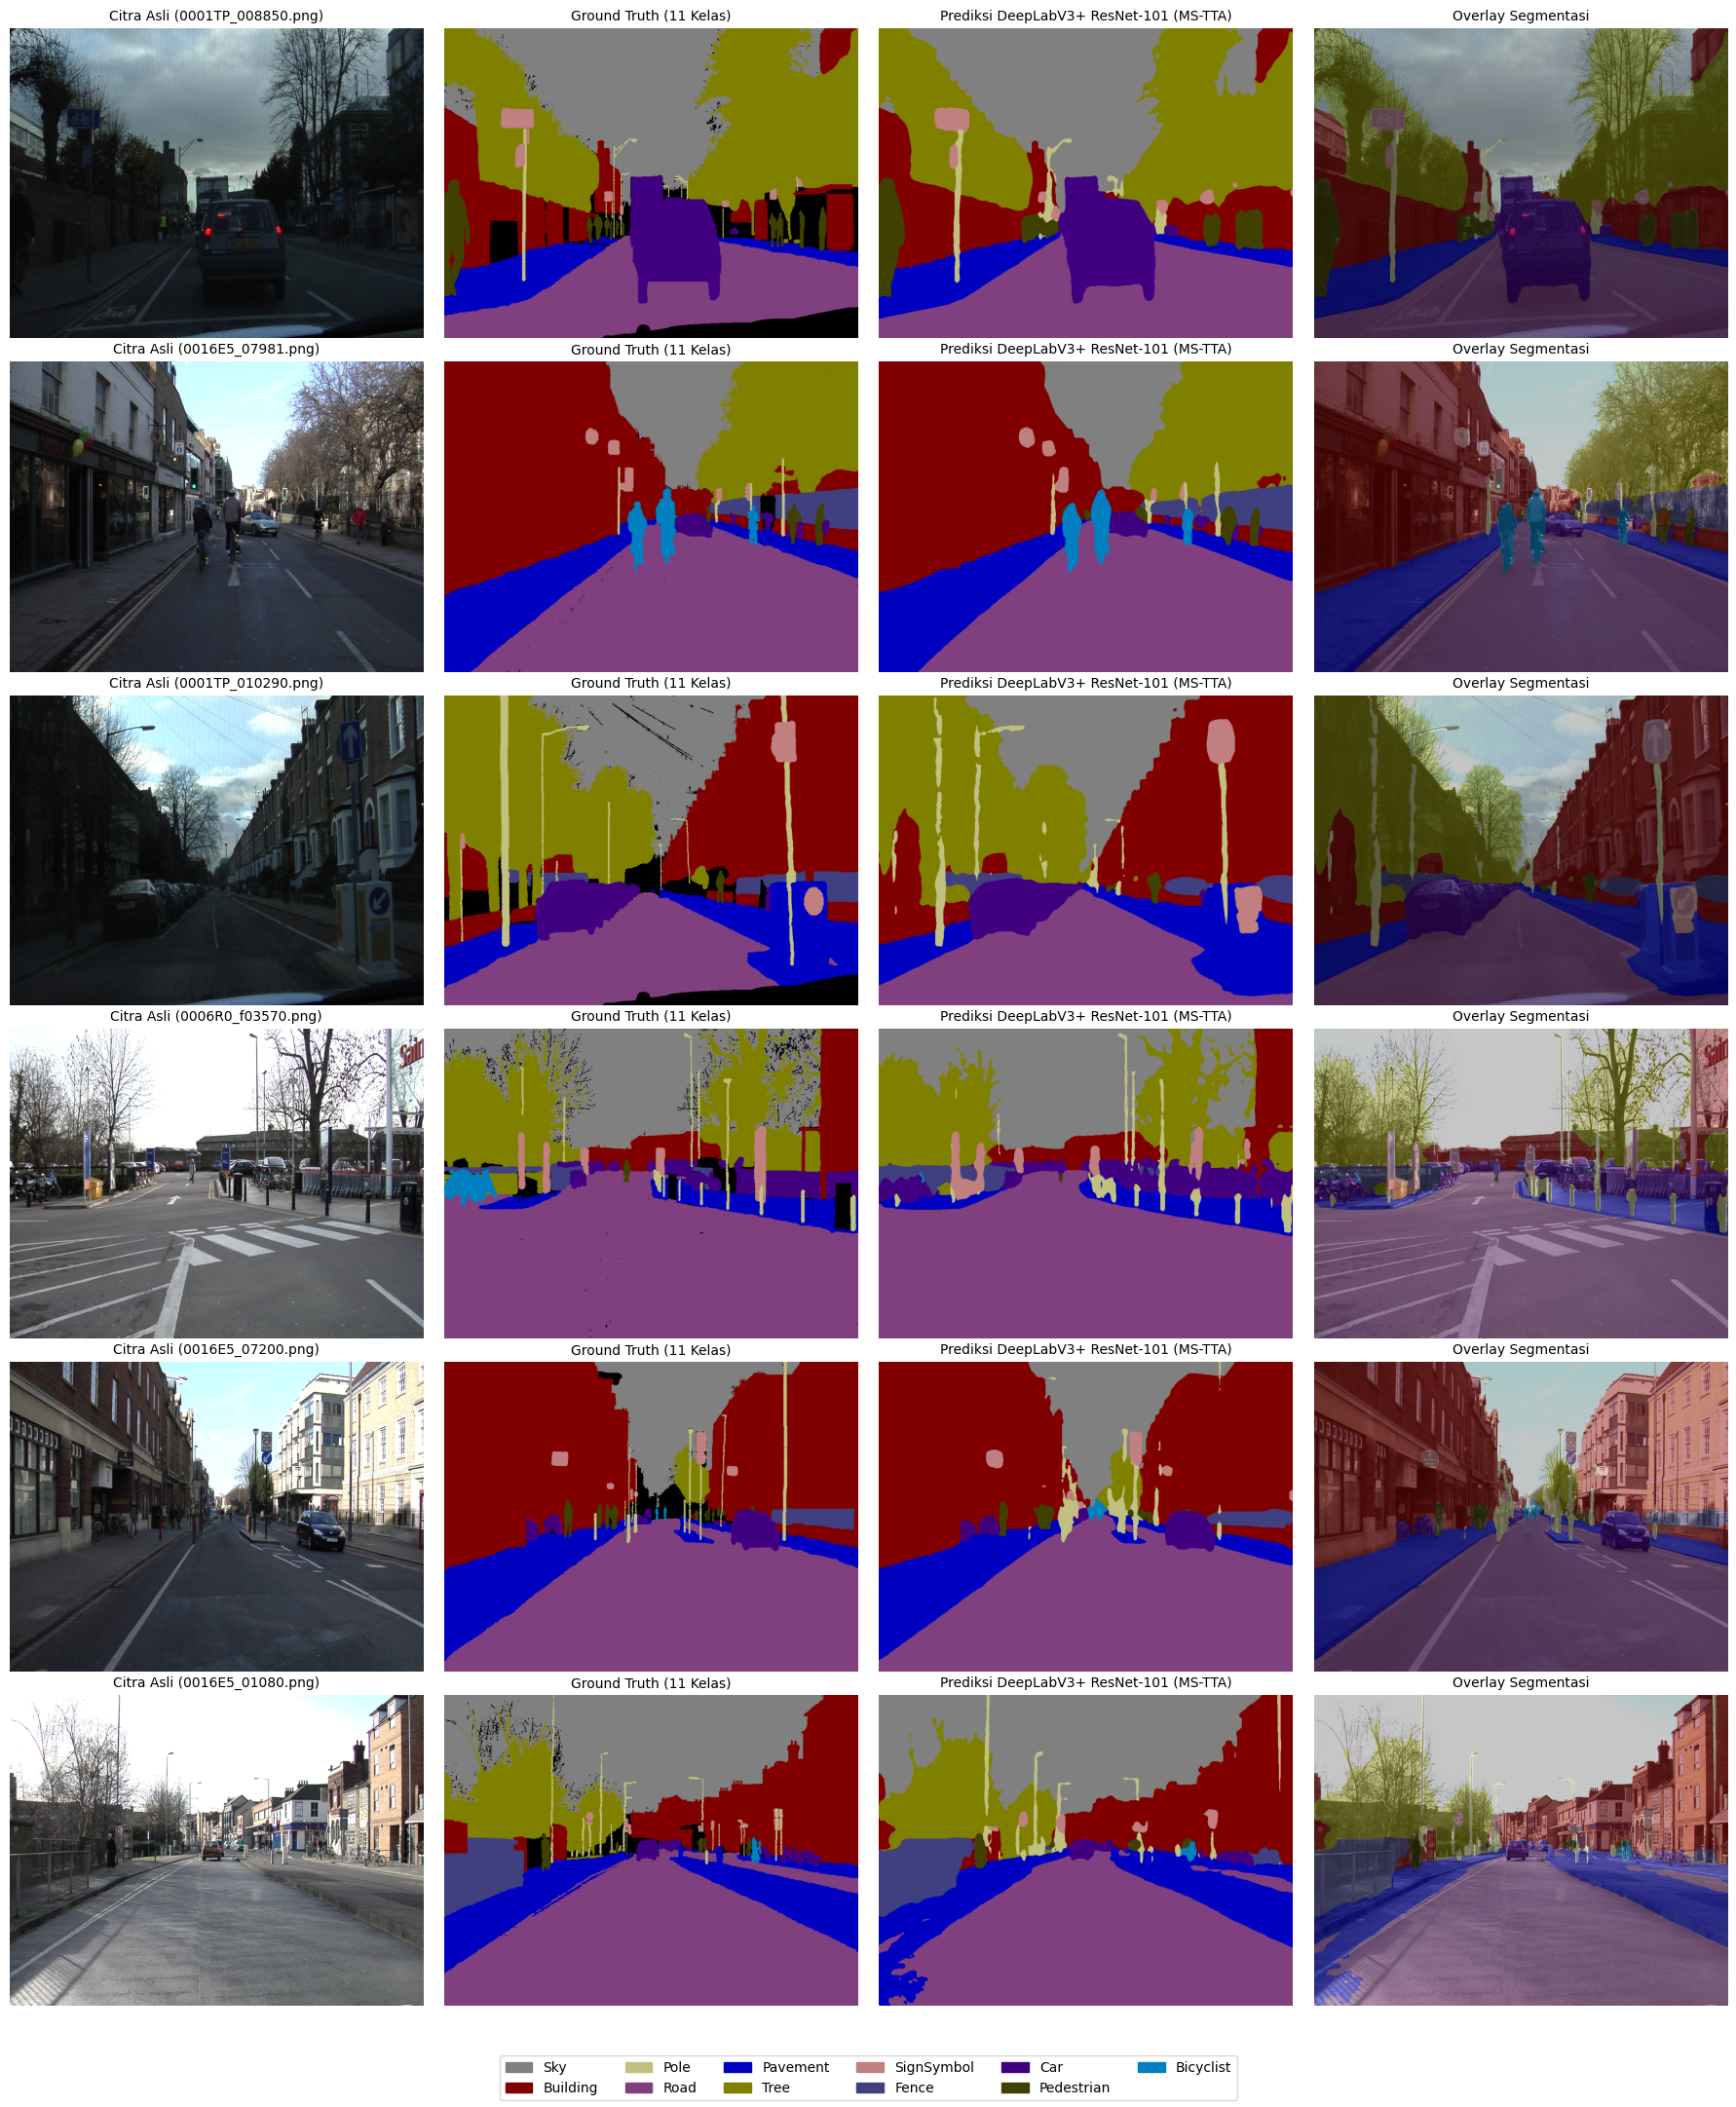

In [ ]:
@torch.no_grad()
def predict_rgb_image(model, img_rgb: np.ndarray, tta_mode="multiscale"):
    orig_h, orig_w = img_rgb.shape[:2]
    resized = cv2.resize(img_rgb, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_LINEAR)
    norm = (resized.astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
    tensor = torch.from_numpy(norm.transpose(2, 0, 1)).unsqueeze(0).to(DEVICE)

    with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
        if tta_mode == "multiscale":
            logits = forward_multiscale_tta(model, tensor, scales=(0.75, 1.0, 1.25))
        elif tta_mode == "flip":
            logits = 0.5 * (model(tensor) + torch.flip(model(torch.flip(tensor, dims=[3])), dims=[3]))
        else:
            logits = model(tensor)

    logits_orig = F.interpolate(logits, size=(orig_h, orig_w), mode="bilinear", align_corners=False)
    pred_ids = torch.argmax(logits_orig, dim=1).squeeze(0).cpu().numpy().astype(np.uint8)
    pred_rgb = class_ids_to_rgb(pred_ids)
    overlay = cv2.addWeighted(img_rgb, 0.55, pred_rgb, 0.45, 0)
    return pred_ids, pred_rgb, overlay


num_samples = min(6, len(test_pairs))
sample_indices = np.linspace(0, len(test_pairs) - 1, num_samples, dtype=int)

fig, axes = plt.subplots(num_samples, 4, figsize=(18, 3.6 * num_samples))
if num_samples == 1:
    axes = np.expand_dims(axes, axis=0)

for row, idx in enumerate(sample_indices):
    img_path, mask_path = test_pairs[idx]
    img_rgb = cv2.cvtColor(cv2.imread(img_path, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    gt_ids = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    gt_rgb = class_ids_to_rgb(gt_ids)

    _, pred_rgb, overlay = predict_rgb_image(model, img_rgb, tta_mode="multiscale")

    axes[row, 0].imshow(img_rgb)
    axes[row, 0].set_title(f"Citra Asli ({Path(img_path).name})", fontsize=10)
    axes[row, 1].imshow(gt_rgb)
    axes[row, 1].set_title("Ground Truth (11 Kelas)", fontsize=10)
    axes[row, 2].imshow(pred_rgb)
    axes[row, 2].set_title("Prediksi DeepLabV3+ ResNet-101 (MS-TTA)", fontsize=10)
    axes[row, 3].imshow(overlay)
    axes[row, 3].set_title("Overlay Segmentasi", fontsize=10)

    for col in range(4):
        axes[row, col].axis("off")

patches = [mpatches.Patch(color=CLASS_COLORS[i] / 255.0, label=CLASS_NAMES[i]) for i in range(NUM_CLASSES)]
fig.legend(handles=patches, loc="lower center", ncol=6, fontsize=10, frameon=True)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(OUTPUT_DIR / "test_predictions_grid_v3.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Uji Inferensi pada Citra Bebas (Opsional: Upload Gambar Jalan/Bus/Rumput)

Ubah `RUN_CUSTOM_UPLOAD = True`

In [12]:
RUN_CUSTOM_UPLOAD = False

if RUN_CUSTOM_UPLOAD:
    from google.colab import files
    uploaded = files.upload()
    for fname in uploaded.keys():
        img_rgb = cv2.cvtColor(cv2.imread(fname, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
        _, pred_rgb, overlay = predict_rgb_image(model, img_rgb, tta_mode="multiscale")

        fig, axes = plt.subplots(1, 3, figsize=(16, 5))
        axes[0].imshow(img_rgb); axes[0].set_title(f"Input: {fname}"); axes[0].axis("off")
        axes[1].imshow(pred_rgb); axes[1].set_title("Mask Segmentasi v3 (11 Kelas)"); axes[1].axis("off")
        axes[2].imshow(overlay); axes[2].set_title("Overlay"); axes[2].axis("off")
        patches = [mpatches.Patch(color=CLASS_COLORS[i] / 255.0, label=CLASS_NAMES[i]) for i in range(NUM_CLASSES)]
        fig.legend(handles=patches, loc="lower center", ncol=6, fontsize=9)
        plt.tight_layout(rect=[0, 0.08, 1, 1])
        plt.show()
else:
    print("Set RUN_CUSTOM_UPLOAD = True untuk mengunggah citra kustom.")

Set RUN_CUSTOM_UPLOAD = True untuk mengunggah citra kustom.
